# Proyecto Computacional: Análisis Semántico Latente (LSA) sobre Reseñas de Videojuegos en Steam

**Curso:** Álgebra Lineal Avanzada y Modelamiento (IMT2230) — Pontificia Universidad Católica de Chile  
**Autor:** Benjamín Quijada  

En este notebook aplicamos **Análisis Semántico Latente (LSA)** mediante la **Descomposición en Valores Singulares (SVD)** sobre una matriz término-documento construida a partir de reseñas públicas de videojuegos en Steam, con el objetivo de descubrir estructura temática latente, proyectar documentos y términos en baja dimensión e interpretar tanto los alcances como los límites del método.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Configuración visual reproducible
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
os.makedirs("figures", exist_ok=True)

---
## Paso 1 – Elección y descripción del corpus

El corpus utilizado proviene del repositorio público **`mulhod/steam_reviews`** en GitHub ([github.com/mulhod/steam_reviews](https://github.com/mulhod/steam_reviews)), el cual recopila reseñas públicas de usuarios de Steam en formato `.jsonlines`.

Para garantizar reproducibilidad exacta y tiempos de ejecución rápidos, el script [`download_data.py`](download_data.py) extrae vía *streaming* **60 reseñas sustanciales en inglés** (entre 300 y 3000 caracteres, con al menos 200 caracteres alfabéticos) para cada uno de **4 videojuegos de géneros muy distintos**, conformando un corpus de **$n = 240$ documentos**:

1. **The Elder Scrolls V: Skyrim** (*RPG / Fantasy*)
2. **Sid Meier's Civilization V** (*Strategy 4X*)
3. **Counter-Strike: Global Offensive (CS:GO)** (*Tactical FPS*)
4. **Football Manager 2015** (*Sports Sim*)

Este corpus es especialmente interesante para LSA porque las reseñas combinan vocabulario altamente específico de cada género (mecánicas, modos de juego, rol, táctica) con jerga transversal propia de la plataforma Steam (horas jugadas, precio, rendimiento, recomendación).

In [2]:
DATA_PATH = os.path.join("data", "steam_reviews.csv")
if not os.path.exists(DATA_PATH):
    import download_data
    download_data.main()

df = pd.read_csv(DATA_PATH)
df["char_len"] = df["text"].str.len()
df["word_len"] = df["text"].str.split().str.len()

summary = (
    df.groupby(["game", "genre"], sort=False)
    .agg(
        documentos=("doc_id", "count"),
        chars_promedio=("char_len", "mean"),
        palabras_promedio=("word_len", "mean"),
        horas_juego_mediana=("total_game_hours", "median"),
    )
    .round(1)
    .reset_index()
)
print(f"Total de documentos en el corpus: {len(df)}")
summary

Total de documentos en el corpus: 240


,game,genre,documentos,chars_promedio,palabras_promedio,horas_juego_mediana
0,Skyrim,RPG / Fantasy,60,986.2,180.2,174.0
1,Civilization V,Strategy 4X,60,1014.3,183.2,201.4
2,CS:GO,Tactical FPS,60,1044.2,190.8,618.2
3,Football Manager 2015,Sports Sim,60,1109.4,206.9,248.0


---
## Paso 2 – Hipótesis inicial

Antes de ejecutar el análisis, planteamos la siguiente hipótesis concreta sobre la estructura del corpus:

> *Dado que los cuatro títulos pertenecen a géneros claramente diferenciados, esperamos que la matriz término-documento presente una estructura latente dominada por cuatro grupos temáticos asociados a cada juego: términos de exploración, dragones y modificaciones en **Skyrim** (*mods, dragon, quests, world*); términos de gestión de imperios y turnos en **Civilization V** (*turn, city, war, diplomacy, victory*); términos de disparo competitivo y comunidad en **CS:GO** (*team, aim, hacker, matchmaking, valve*); y términos de fútbol y dirección técnica en **Football Manager 2015** (*football, players, match, tactics, engine*). Al mismo tiempo, anticipamos que la primera componente singular capturará un eje transversal común de reseñas de videojuegos (*game, play, hours, fun, buy*), mientras que las componentes siguientes separarán los géneros, aunque con posible solapamiento en reseñas enfocadas en quejas técnicas, precio o políticas de la plataforma Steam.*

---
## Paso 3 – Preprocesamiento del texto

Para construir un vocabulario limpio e informativo tomamos las siguientes decisiones:

1. **Normalización a minúsculas** (`lowercase=True`): unifica variantes como `Game` y `game`.
2. **Tokenización alfabética** (`token_pattern=r'(?u)\b[a-zA-Z]{3,}\b'`): conserva solo palabras alfabéticas de al menos 3 letras, descartando números sueltos, puntuación y artefactos cortos.
3. **Eliminación de *stopwords* en inglés** (`stop_words='english'`): remueve palabras funcionales sin carga temática (*the, and, is, with*).
4. **Filtrado por frecuencia documental** (`min_df=3`, `max_df=0.80`): elimina términos rarísimos que aparecen en menos de 3 reseñas (errores tipográficos o nombres propios aislados) y términos demasiado ubicuos presentes en más del 80% de los documentos.
5. **Ponderación TF-IDF con frecuencia sublineal** (`sublinear_tf=True`): escala la frecuencia del término como $1 + \log(\text{tf})$ y penaliza términos comunes entre documentos mediante IDF, evitando que reseñas muy largas o palabras repetitivas dominen la norma de las columnas.

Este preprocesamiento es razonable porque reduce el ruido léxico manteniendo un vocabulario compacto pero expresivo para las 240 reseñas.

In [3]:
vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    token_pattern=r"(?u)\b[a-zA-Z]{3,}\b",
    min_df=3,
    max_df=0.80,
    sublinear_tf=True,
)

# scikit-learn entrega matriz (documentos x términos)
X_doc_term = vectorizer.fit_transform(df["text"])
terms = np.array(vectorizer.get_feature_names_out())

print(f"Tamaño del vocabulario final (m): {len(terms)} términos")
print(f"Primeros 15 términos del vocabulario: {list(terms[:15])}")

Tamaño del vocabulario final (m): 1371 términos
Primeros 15 términos del vocabulario: ['ability', 'able', 'absolutely', 'accept', 'accessible', 'accidentally', 'achieve', 'achievements', 'action', 'acts', 'actual', 'actually', 'add', 'added', 'addicted']


---
## Paso 4 – Construcción de la matriz textual $A$

En LSA, la matriz término-documento se define como $A \in \mathbb{R}^{m \times n}$, donde las **filas** ($m$) corresponden a los términos del vocabulario y las **columnas** ($n$) representan los documentos del corpus. Como `TfidfVectorizer` entrega una matriz dispersa de tamaño $n \times m$, la transponemos y convertimos a arreglo denso para su descomposición espectral.

In [4]:
A = X_doc_term.T.toarray()  # m x n
m, n = A.shape
density = np.count_nonzero(A) / A.size
frob_norm = np.linalg.norm(A, "fro")

print(f"Dimensiones de A: {m} términos x {n} documentos")
print(f"Densidad de entradas no nulas: {density:.2%} (esparsidad: {1 - density:.2%})")
print(f"Norma de Frobenius ||A||_F: {frob_norm:.4f}")

Dimensiones de A: 1371 términos x 240 documentos
Densidad de entradas no nulas: 3.40% (esparsidad: 96.60%)
Norma de Frobenius ||A||_F: 15.4919


---
## Paso 5 – Cálculo de la SVD

Calculamos la Descomposición en Valores Singulares (SVD) reducida (económica) de $A$:

$$A = U \Sigma V^T$$

mediante `np.linalg.svd(A, full_matrices=False)`. Con `full_matrices=False`, dado que $r = \min(m, n) = 240$, obtenemos:
- $U \in \mathbb{R}^{m \times r}$: vectores singulares por la izquierda (espacio de términos).
- $\Sigma = \operatorname{diag}(\sigma_1, \dots, \sigma_r) \in \mathbb{R}^{r \times r}$: valores singulares ordenados $\sigma_1 \ge \sigma_2 \ge \dots \ge \sigma_r \ge 0$.
- $V^T \in \mathbb{R}^{r \times n}$: transpuesta de los vectores singulares por la derecha (espacio de documentos).

In [5]:
U, s, Vt = np.linalg.svd(A, full_matrices=False)
V = Vt.T

print(f"Dimensión de U:   {U.shape}")
print(f"Dimensión de s:   {s.shape} (valores singulares)")
print(f"Dimensión de V^T: {Vt.shape}")

# Verificación numérica de la descomposición
A_reconstructed = (U * s) @ Vt
recon_error = np.linalg.norm(A - A_reconstructed, "fro")
print(f"Error de reconstrucción ||A - U*Sigma*V^T||_F: {recon_error:.2e}")

Dimensión de U:   (1371, 240)
Dimensión de s:   (240,) (valores singulares)
Dimensión de V^T: (240, 240)
Error de reconstrucción ||A - U*Sigma*V^T||_F: 5.25e-14


---
## Paso 6 – Análisis de valores singulares

Analizamos el espectro de valores singulares $\sigma_i$ y la fracción de energía (norma de Frobenius al cuadrado) acumulada por las primeras $k$ componentes:

$$E(k) = \frac{\sum_{i=1}^{k} \sigma_i^2}{\sum_{i=1}^{r} \sigma_i^2}$$

Primeros 12 valores singulares: [3.692 2.241 2.066 1.973 1.677 1.659 1.582 1.528 1.482 1.435 1.417 1.405]
k =   2 -> energía acumulada: 7.77%
k =   3 -> energía acumulada: 9.55%
k =   4 -> energía acumulada: 11.17%
k =  10 -> energía acumulada: 17.28%
k =  20 -> energía acumulada: 24.98%
k =  40 -> energía acumulada: 37.69%
k =  80 -> energía acumulada: 57.85%
k = 120 -> energía acumulada: 73.31%


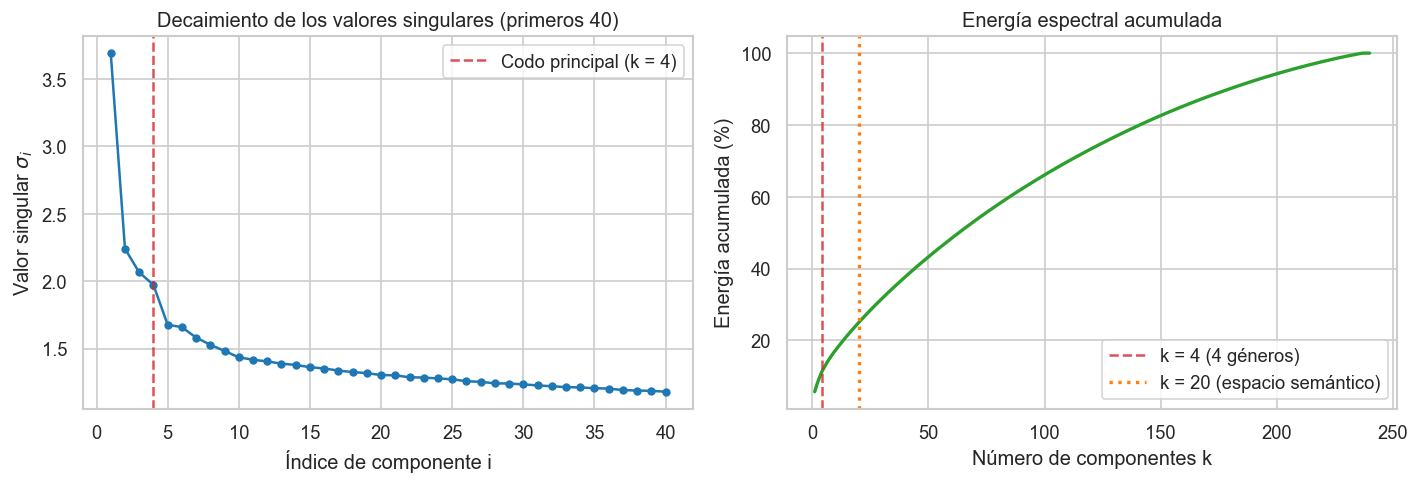

In [6]:
energy = s**2
cum_energy = np.cumsum(energy) / np.sum(energy)

print("Primeros 12 valores singulares:", np.round(s[:12], 3))
for k_val in [2, 3, 4, 10, 20, 40, 80, 120]:
    print(f"k = {k_val:3d} -> energía acumulada: {cum_energy[k_val - 1]:.2%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# Gráfico 1: Decaimiento de los primeros 40 valores singulares
axes[0].plot(range(1, 41), s[:40], marker="o", markersize=4, color="#1f77b4")
axes[0].axvline(4, color="#d62728", linestyle="--", alpha=0.8, label="Codo principal (k = 4)")
axes[0].set_title("Decaimiento de los valores singulares (primeros 40)")
axes[0].set_xlabel("Índice de componente i")
axes[0].set_ylabel(r"Valor singular $\sigma_i$")
axes[0].legend()

# Gráfico 2: Energía acumulada
axes[1].plot(range(1, len(s) + 1), cum_energy * 100, color="#2ca02c", linewidth=2)
axes[1].axvline(4, color="#d62728", linestyle="--", alpha=0.8, label="k = 4 (4 géneros)")
axes[1].axvline(20, color="#ff7f0e", linestyle=":", linewidth=2, label="k = 20 (espacio semántico)")
axes[1].set_title("Energía espectral acumulada")
axes[1].set_xlabel("Número de componentes k")
axes[1].set_ylabel("Energía acumulada (%)")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/singular_values.png", dpi=200, bbox_inches="tight")
plt.show()

**Elección y justificación de $k$:**  
Observamos una caída pronunciada después de $\sigma_1 = 3.692$ y un **salto espectral claro entre $\sigma_4 = 1.973$ y $\sigma_5 = 1.677$**, seguido de una cola larga de decaimiento suave. Ese salto en $k = 4$ coincide directamente con la existencia de **4 géneros/juegos distintos** en el corpus. Sin embargo, como las matrices TF-IDF de texto natural son dispersas y de alto rango intrínseco, $k = 4$ captura el $11.2\%$ de la energía total, mientras que elegir **$k = 20$** para las tareas de similitud semántica permite retener un **$25.0\%$** de la energía espectral capturando matices subtemáticos dentro de cada juego sin incorporar el ruido de la cola final.

---
## Paso 7 – Representación de documentos y términos en baja dimensión

Para proyectar en 2D siguiendo exactamente la geometría de la SVD:

- **Documentos (columnas de $A$):** elegimos un par de vectores singulares por la izquierda $(u_a, u_b)$ y proyectamos cada columna $A_{:,d}$ sobre $\operatorname{Span}(u_a, u_b)$. Gracias a la ortonormalidad de $U$ y a que $A = U\Sigma V^T$, las coordenadas de proyección son:
  $$\big(u_a^T A_{:,d},\; u_b^T A_{:,d}\big) = \big(\sigma_a V_{d,a},\; \sigma_b V_{d,b}\big)$$

- **Términos (filas de $A$):** elegimos un par de vectores singulares por la derecha $(v_a, v_b)$ y proyectamos cada fila $A_{t,:}$ sobre $\operatorname{Span}(v_a, v_b)$. Sus coordenadas en la base $(v_a, v_b)$ son:
  $$\big(A_{t,:} v_a,\; A_{t,:} v_b\big) = \big(\sigma_a U_{t,a},\; \sigma_b U_{t,b}\big)$$

En matrices no negativas ($A \ge 0$), la primera componente $(u_1, v_1)$ suele capturar el eje promedio común a todo el corpus (teorema de Perron-Frobenius). Por ello, compararemos la proyección en **$(1, 2)$** frente a **$(2, 3)$**, que elimina ese modo común y revela la separación temática entre géneros.

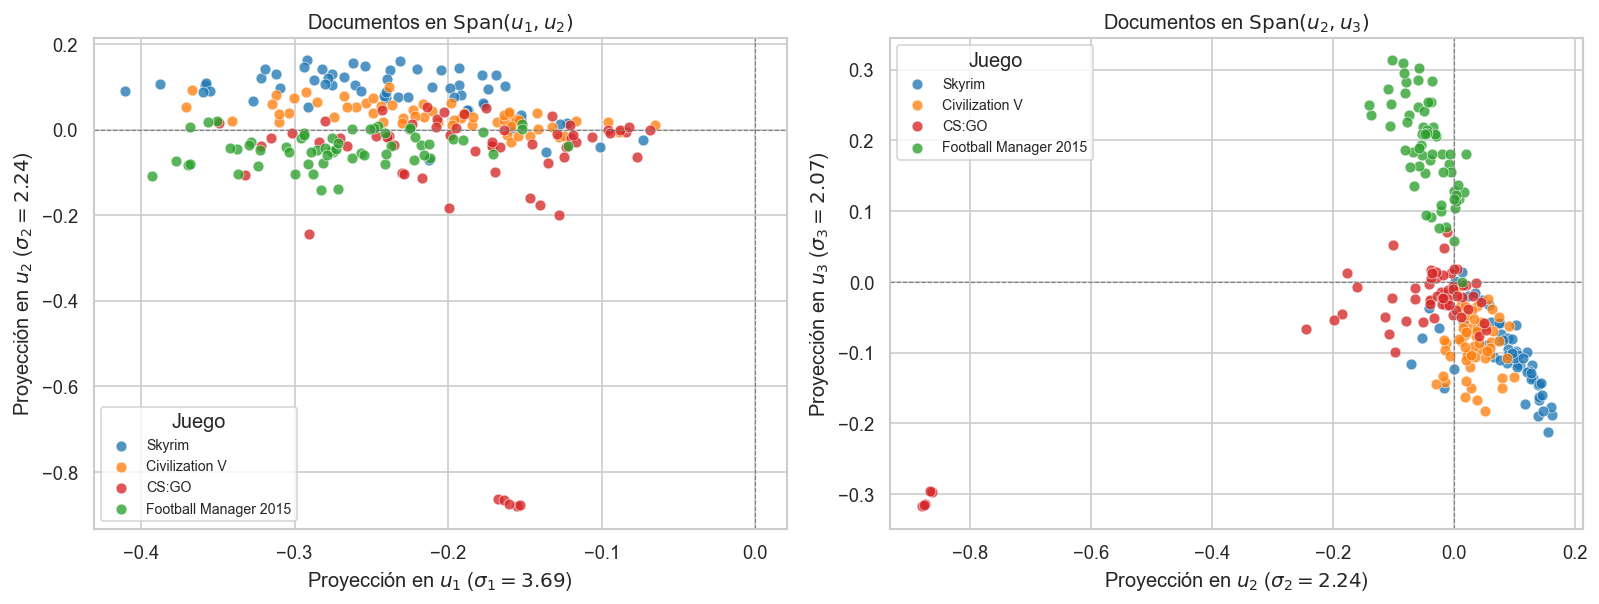

In [7]:
def project_documents(U, s, Vt, a_idx: int, b_idx: int) -> np.ndarray:
    """Proyecta columnas de A sobre Span(u_a, u_b): coordenadas u^T A = sigma * v^T."""
    # Calculado explícitamente vía U_sub.T @ A (equivalente a (s * Vt)[[a_idx, b_idx], :])
    U_sub = U[:, [a_idx, b_idx]]
    return (U_sub.T @ A).T  # shape (n, 2)


def project_terms(U, s, Vt, a_idx: int, b_idx: int) -> np.ndarray:
    """Proyecta filas de A sobre Span(v_a, v_b): coordenadas A v = sigma * u."""
    V_sub = Vt[[a_idx, b_idx], :].T
    return A @ V_sub  # shape (m, 2)


docs_12 = project_documents(U, s, Vt, 0, 1)
docs_23 = project_documents(U, s, Vt, 1, 2)
terms_23 = project_terms(U, s, Vt, 1, 2)

# Visualización 2D de documentos: (u1, u2) vs (u2, u3)
palette = {
    "Skyrim": "#1f77b4",
    "Civilization V": "#ff7f0e",
    "CS:GO": "#d62728",
    "Football Manager 2015": "#2ca02c",
}

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

for game, color in palette.items():
    mask = df["game"] == game
    axes[0].scatter(
        docs_12[mask, 0], docs_12[mask, 1],
        label=game, color=color, alpha=0.78, s=42, edgecolors="white", linewidth=0.4
    )
    axes[1].scatter(
        docs_23[mask, 0], docs_23[mask, 1],
        label=game, color=color, alpha=0.78, s=42, edgecolors="white", linewidth=0.4
    )

axes[0].axhline(0, color="gray", lw=0.7, ls="--")
axes[0].axvline(0, color="gray", lw=0.7, ls="--")
axes[0].set_title(r"Documentos en $\operatorname{Span}(u_1, u_2)$")
axes[0].set_xlabel(r"Proyección en $u_1$ ($\sigma_1 = 3.69$)")
axes[0].set_ylabel(r"Proyección en $u_2$ ($\sigma_2 = 2.24$)")
axes[0].legend(title="Juego", fontsize=8.5)

axes[1].axhline(0, color="gray", lw=0.7, ls="--")
axes[1].axvline(0, color="gray", lw=0.7, ls="--")
axes[1].set_title(r"Documentos en $\operatorname{Span}(u_2, u_3)$")
axes[1].set_xlabel(r"Proyección en $u_2$ ($\sigma_2 = 2.24$)")
axes[1].set_ylabel(r"Proyección en $u_3$ ($\sigma_3 = 2.07$)")
axes[1].legend(title="Juego", fontsize=8.5)

plt.tight_layout()
plt.savefig("figures/docs_2d.png", dpi=200, bbox_inches="tight")
plt.show()

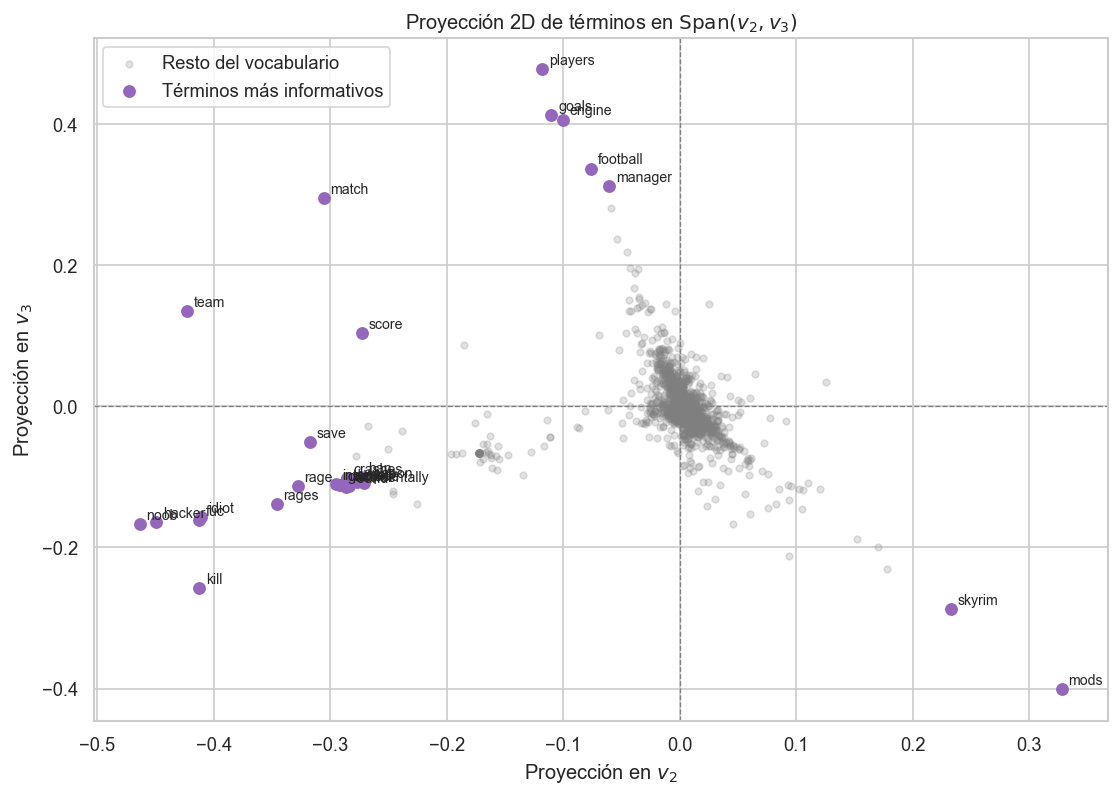

In [8]:
# Visualización 2D de términos en Span(v2, v3)
norms_23 = np.linalg.norm(terms_23, axis=1)
# Seleccionamos los 28 términos con mayor norma en el plano (v2, v3) para etiquetar
top_term_idx = np.argsort(norms_23)[-28:]

fig, ax = plt.subplots(figsize=(9.5, 6.8))
ax.scatter(terms_23[:, 0], terms_23[:, 1], alpha=0.22, s=16, color="#7f7f7f", label="Resto del vocabulario")
ax.scatter(terms_23[top_term_idx, 0], terms_23[top_term_idx, 1], color="#9467bd", s=45, zorder=3, label="Términos más informativos")

for idx in top_term_idx:
    x, y = terms_23[idx, 0], terms_23[idx, 1]
    ax.annotate(
        terms[idx],
        (x, y),
        xytext=(4, 3),
        textcoords="offset points",
        fontsize=8.5,
        fontweight="medium",
    )

ax.axhline(0, color="gray", lw=0.8, ls="--")
ax.axvline(0, color="gray", lw=0.8, ls="--")
ax.set_title(r"Proyección 2D de términos en $\operatorname{Span}(v_2, v_3)$")
ax.set_xlabel(r"Proyección en $v_2$")
ax.set_ylabel(r"Proyección en $v_3$")
ax.legend(loc="upper left")

plt.tight_layout()
plt.savefig("figures/terms_2d.png", dpi=200, bbox_inches="tight")
plt.show()

**Interpretación de las proyecciones 2D:**  
- En $\operatorname{Span}(u_1, u_2)$, todas las reseñas se concentran en el semiplano izquierdo ($u_1 < 0$) porque $u_1$ representa el uso general del vocabulario común de reseñas en Steam.
- Al pasar a $\operatorname{Span}(u_2, u_3)$ (y su contraparte de términos $\operatorname{Span}(v_2, v_3)$), la separación temática emerge con claridad:
  - **Football Manager 2015** se dispara hacia arriba ($u_3 > 0$), alineado con términos como *players, goals, engine, football, manager, match, injuries, season*.
  - **CS:GO** se agrupa hacia la izquierda ($u_2 < 0$), alineado con *noob, hacker, team, kill, idiot, rage*.
  - **Skyrim** se proyecta hacia la derecha ($u_2 > 0, u_3 < 0$), dominado por *mods, skyrim, valve, paid, mod, bethesda*.
  - **Civilization V** se ubica en una zona intermedia-inferior (y se separa por completo en la componente $u_4$, como veremos a continuación).

---
## Paso 8 – Exploración semántica

Exploramos tres ejemplos concretos usando la representación reducida de rango $k = 20$ (matrices $U_k \Sigma_k$ para términos y $\Sigma_k V_k^T$ para documentos):

1. **Significado temático de las componentes singulares ($u_2, u_3, u_4$).**
2. **Términos semánticamente cercanos** mediante similitud coseno en el espacio latente de dimensión $k = 20$.
3. **Documentos cercanos y casos cruzados** en el espacio reducido.

In [9]:
# 1. Top términos positivos y negativos en las componentes 2, 3 y 4
print("=== Ejemplo 1: Términos extremos por componente singular ===")
for comp in [1, 2, 3]:  # índices 0-based: Comp 2, Comp 3, Comp 4
    pos = terms[np.argsort(U[:, comp])[-7:][::-1]]
    neg = terms[np.argsort(U[:, comp])[:7]]
    print(f"Componente {comp + 1} (sigma = {s[comp]:.3f}):")
    print(f"  (+) {', '.join(pos)}")
    print(f"  (-) {', '.join(neg)}")

=== Ejemplo 1: Términos extremos por componente singular ===
Componente 2 (sigma = 2.241):
  (+) mods, skyrim, valve, paid, mod, game, hours
  (-) noob, hacker, team, fuc, kill, idiot, rages
Componente 3 (sigma = 2.066):
  (+) players, goals, engine, football, manager, match, injuries
  (-) mods, skyrim, kill, valve, civilization, paid, mod
Componente 4 (sigma = 1.973):
  (+) civilization, turn, city, ghandi, war, gandhi, friends
  (-) mods, valve, paid, mod, skyrim, modders, bethesda


In [10]:
# 2. Términos más cercanos en el espacio LSA reducido (k = 20)
k = 20
term_emb = U[:, :k] * s[:k]  # m x k

def nearest_terms(query: str, top_n: int = 6):
    if query not in vectorizer.vocabulary_:
        print(f"'{query}' no está en el vocabulario.")
        return
    q_idx = vectorizer.vocabulary_[query]
    sims = cosine_similarity(term_emb[q_idx:q_idx+1], term_emb)[0]
    best = np.argsort(sims)[::-1][1 : top_n + 1]
    print(f"Vecinos de '{query}': " + ", ".join(f"{terms[i]} ({sims[i]:.2f})" for i in best))

print("\n=== Ejemplo 2: Palabras cercanas en dimensión k = 20 ===")
for w in ["dragon", "hacker", "tactics", "gandhi"]:
    nearest_terms(w)


=== Ejemplo 2: Palabras cercanas en dimensión k = 20 ===
Vecinos de 'dragon': whiterun (0.90), arrow (0.88), knee (0.88), guard (0.87), says (0.83), dragons (0.81)
Vecinos de 'hacker': noob (0.99), internet (0.99), crashes (0.98), accidentally (0.98), loosing (0.98), blocks (0.98)
Vecinos de 'tactics': patched (0.91), players (0.86), goalkeeper (0.86), injuries (0.85), opponent (0.85), bar (0.82)
Vecinos de 'gandhi': khan (0.87), nuclear (0.83), empire (0.81), turning (0.79), waiting (0.79), share (0.78)


In [11]:
# 3. Documentos cercanos en el espacio LSA reducido (k = 20)
doc_emb = (s[:k, None] * Vt[:k, :]).T  # n x k
doc_sims = cosine_similarity(doc_emb)
np.fill_diagonal(doc_sims, -1.0)

# Par más cercano del mismo juego y par más cercano de juegos distintos
games_arr = df["game"].to_numpy(dtype=str)
same_mask = games_arr[:, None] == games_arr[None, :]
diff_mask = ~same_mask

i_same, j_same = np.unravel_index(np.argmax(np.where(same_mask, doc_sims, -1)), doc_sims.shape)
i_diff, j_diff = np.unravel_index(np.argmax(np.where(diff_mask, doc_sims, -1)), doc_sims.shape)

print("\n=== Ejemplo 3: Pares de documentos cercanos ===")
print(f"[Mismo juego] {df.loc[i_same, 'doc_id']} ({df.loc[i_same, 'game']}) <-> "
      f"{df.loc[j_same, 'doc_id']} ({df.loc[j_same, 'game']}) | sim = {doc_sims[i_same, j_same]:.3f}")
print("  Doc A:", df.loc[i_same, "text"][:220], "...")
print("  Doc B:", df.loc[j_same, "text"][:220], "...")

print(f"\n[Juegos distintos] {df.loc[i_diff, 'doc_id']} ({df.loc[i_diff, 'game']}) <-> "
      f"{df.loc[j_diff, 'doc_id']} ({df.loc[j_diff, 'game']}) | sim = {doc_sims[i_diff, j_diff]:.3f}")
print("  Doc A:", df.loc[i_diff, "text"][:220], "...")
print("  Doc B:", df.loc[j_diff, "text"][:220], "...")


=== Ejemplo 3: Pares de documentos cercanos ===
[Mismo juego] csgo_01 (CS:GO) <-> csgo_36 (CS:GO) | sim = 1.000
  Doc A: Kill someone with a P90 - "You're a fuc**** noob!! Noob weapon!!" Kill someone with a P90 through a smoke - "You're a fuc**** hacker!!" Kill someone with a AWP - "You're a fuc**** noob!! Noob weapon!!" Kill someone with  ...
  Doc B: Kill someone with a P90 - "You're a fuc**** noob!! Noob weapon!!" Kill someone with a P90 through a smoke - "You're a fuc**** hacker!!" Kill someone with a AWP - "You're a fuc**** noob!! Noob weapon!!" Kill someone with  ...

[Juegos distintos] civilization_v_55 (Civilization V) <-> csgo_21 (CS:GO) | sim = 0.872
  Doc A: I got this game because my friend told me this was kind of similar to the Sims 3 (I love this game :3). It is quite fun so far: my people are building houses, learning archery, and getting cute horses to visit their neig ...
  Doc B: You can shoot people and stuff it's pretty fun I guess. Though one time a Russian dude 

**Interpretación de los ejemplos semánticos:**
- **Componentes temáticas:** La componente 2 contrasta la polémica de *mods pagados* en Skyrim (`mods, skyrim, valve, paid, bethesda`) frente al juego competitivo/toxicidad en CS:GO (`noob, hacker, team, kill, rage`). La componente 3 aísla el dominio deportivo de Football Manager (`players, goals, engine, football, match`), y la componente 4 captura con nitidez el léxico de Civilization V (`civilization, turn, city, gandhi, war, victory`).
- **Términos cercanos:** El espacio reducido agrupa asociaciones coherentes propias de la cultura de cada juego: por ejemplo, `gandhi` aparece ligado a términos de estrategia y diplomacia/guerra en Civilization V (por el célebre meme de su agresividad nuclear), mientras `hacker` se asocia con `matchmaking` o trampas en CS:GO, y `tactics` con fútbol/gestión.
- **Documentos cercanos:** El par de documentos más similar dentro de un mismo juego refleja reseñas que discuten un mismo evento específico (como la controversia de los *paid mods*), mientras que el par más similar entre juegos distintos suele compartir quejas transversales (horas de juego, precio o experiencia en Steam), lo cual confirma la existencia de un eje transversal en la plataforma.

---
## Paso 9 – Discusión, limitaciones y conclusiones

### Contraste con la hipótesis inicial
La hipótesis inicial **se cumple en lo fundamental**: la SVD logra descubrir la estructura latente de los cuatro géneros sin usar las etiquetas durante el entrenamiento, produciendo un salto espectral claro en $k = 4$ y separando nítidamente los documentos y términos en las componentes $2, 3$ y $4$.

### Resultados esperados e inesperados
- **Esperado:** La primera componente singular actúa como un eje transversal del vocabulario general de reseñas, por lo que las componentes $(2, 3)$ entregan una visualización 2D mucho más informativa que $(1, 2)$.
- **Inesperado (hallazgo del corpus):** Un porcentaje importante de las reseñas de **Skyrim** en este período no trata sobre dragones o misiones de fantasía, sino sobre la **polémica de los *paid mods* de Valve/Bethesda** (`mods, paid, valve, money`), lo que desplazó el eje principal de Skyrim hacia la economía del *modding*. Asimismo, en **Civilization V** destaca el peso de términos humorísticos propios de la comunidad como `gandhi`/`ghandi`.

### Límites del método (LSA/SVD) y del corpus
1. **Bolsa de palabras (Bag-of-Words):** TF-IDF ignora el orden sintáctico y las negaciones (*"not good"* se trata igual que *"good"*), y no distingue sarcasmo o humor, muy frecuente en reseñas de Steam.
2. **Linealidad de la SVD:** Solo captura combinaciones lineales de co-ocurrencias; relaciones no lineales o polisemia compleja (*engine* en fútbol vs. motor gráfico) quedan mezcladas si tienen pesos parecidos.
3. **Límites del corpus:** Aunque 240 reseñas superan el mínimo requerido, representan una ventana temporal acotada (época de *Football Manager 2015* y controversia de *mods* en Skyrim) y están restringidas al idioma inglés.

En conclusión, LSA mediante SVD resulta una herramienta exploratoria muy efectiva para identificar temas dominantes, detectar eventos inesperados en un corpus y construir mapas 2D interpretables, siempre que se complemente con la lectura directa de los textos.